# Metin Sınıflandırma: Siber Zorbalık Türleri

**Veri:**
1. **İngilizce tweetler:** ~47.700 tweet, 6 sınıf (yaş, etnisite, cinsiyet, din, diğer zorbalık, zorbalık değil)
2. **Bangla sosyal medya yorumları (BanglaHarassNet):** ~5.800 yorum, 5 sınıf

**Yöntem:**
1. Metni **TF-IDF** ile sayılara çeviriyoruz (her kelimeye/harf parçasına bir önem puanı).
2. **Lojistik regresyon** ile sınıfı tahmin ediyoruz.
3. Verinin %80'iyle eğitip %20'siyle test ediyoruz.


In [20]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
# Grafik ayarları: tüm grafikler aynı görünsün diye
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})
MAVI, TURUNCU = "#2a78d6", "#eb6834"

### Dosya yolları

In [22]:
TWEET_DOSYASI  = Path("veriler") / "cyberbullying_tweets.csv" / "cyberbullying_tweets.csv"
BANGLA_KLASORU = Path("veriler") / "BanglaHarassNet A Multi-Platform Annotated Dataset"

## Yardımcı Fonksiyonlar

Aynı adımları iki veri setinde de kullanacağımız için onları bir kez fonksiyon olarak yazıyoruz.

**`normalize_et`:** Aynı metnin küçük farklarla (büyük harf, link, @kullanıcı, noktalama) tekrar etmesini yakalamak için metni sadeleştirir. Bu sadeleştirilmiş metin yalnızca tekrarları bulmak için kullanılır; model orijinal metinle eğitilir.

**Bangla için önemli düzeltme:** Python'da `\w` ("harf") ifadesi Bangla'daki ünlü işaretlerini harf saymaz. Bu yüzden noktalama silerken bu işaretler de siliniyor


In [23]:
def normalize_et(metin):
    metin = str(metin).lower() 
    metin = re.sub(r"^rt ", "", metin)  # baştaki 'rt' (retweet) ifadesini sil
    metin = re.sub(r"http\S+|www\.\S+", " ", metin) # linkleri sil
    metin = re.sub(r"@\w+", " ", metin)  # @kullanıcı adlarını sil
    metin = re.sub(r"[^\w\s\u0980-\u09FF]", " ", metin)  # noktalama ve emojileri sil (Bangla harflerini koru)
    metin = re.sub(r"\s+", " ", metin) # fazla boşlukları teke indir
    return metin.strip()

# Örnek
print(normalize_et("RT @ali: Merhaba!!! https://t.co/abc"))
print(normalize_et("কি"), "≠", normalize_et("কে"))

merhaba
কি ≠ কে


**veriyi_temizle:** 
- Boş metinleri atar.
- **Çelişkili etiketleri** atar: aynı metin farklı sınıflarla etiketlenmişse hangisinin doğru olduğunu bilemeyiz, bu yüzden hepsini çıkarırız.
- Kalan tekrarları atar (her metinden bir tane kalır).

In [24]:
def veriyi_temizle(veri, metin_sutunu, etiket_sutunu):
    print("Başlangıçtaki satır sayısı :", len(veri))

    veri = veri.dropna(subset=[metin_sutunu]).copy()
    veri["norm_metin"] = veri[metin_sutunu].map(normalize_et)
    veri = veri[veri["norm_metin"] != ""]

    # Her metin kaç farklı etiketle geçiyor? 1'den fazlaysa çelişkili.
    etiket_sayisi = veri.groupby("norm_metin")[etiket_sutunu].transform("nunique")
    celiskili = etiket_sayisi > 1
    print("Çelişkili etiketli satır:", celiskili.sum())
    veri = veri[~celiskili]

    tekrar = veri["norm_metin"].duplicated()
    print("Tekrar eden satır:", tekrar.sum())
    veri = veri[~tekrar]

    print("Temizlik sonrası satır:", len(veri))
    return veri

In [25]:
def sinif_dagilimi_grafigi(etiketler, baslik, dosya_adi):
    sayilar = etiketler.value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(sayilar) + 1))
    ax.barh(sayilar.index, sayilar.values, color=MAVI, height=0.6)
    for i, deger in enumerate(sayilar.values):
        ax.text(deger, i, f" {deger}", va="center")
    ax.set_title(baslik, loc="left")
    ax.set_xlabel("Örnek sayısı")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()


def karisiklik_matrisi_grafigi(gercek, tahmin, baslik, dosya_adi):
    """Satırlar gerçek sınıf, sütunlar tahmin. Her satır %100'e tamamlanır."""
    siniflar = sorted(gercek.unique())
    matris = confusion_matrix(gercek, tahmin, labels=siniflar, normalize="true") * 100

    fig, ax = plt.subplots(figsize=(1.1 * len(siniflar) + 2.5, 0.9 * len(siniflar) + 1.5))
    ax.imshow(matris, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(siniflar)):
        for j in range(len(siniflar)):
            renk = "white" if matris[i, j] > 60 else "black"
            ax.text(j, i, f"{matris[i, j]:.0f}", ha="center", va="center", color=renk, fontsize=9)
    ax.set_xticks(range(len(siniflar)), siniflar, rotation=35, ha="right")
    ax.set_yticks(range(len(siniflar)), siniflar)
    ax.set_xlabel("Modelin tahmini")
    ax.set_ylabel("Gerçek sınıf")
    ax.set_title(baslik + "\n(satır yüzdesi; köşegen = doğru bilinen oran)", loc="left")
    ax.grid(False)
    plt.tight_layout()
    plt.show()

## Bölüm 1: İngilizce Tweetler
### 1.1 Veriyi okuma ve temizleme

Başlangıçtaki satır sayısı : 47692
Çelişkili etiketli satır: 3514
Tekrar eden satır: 625
Temizlik sonrası satır: 43265


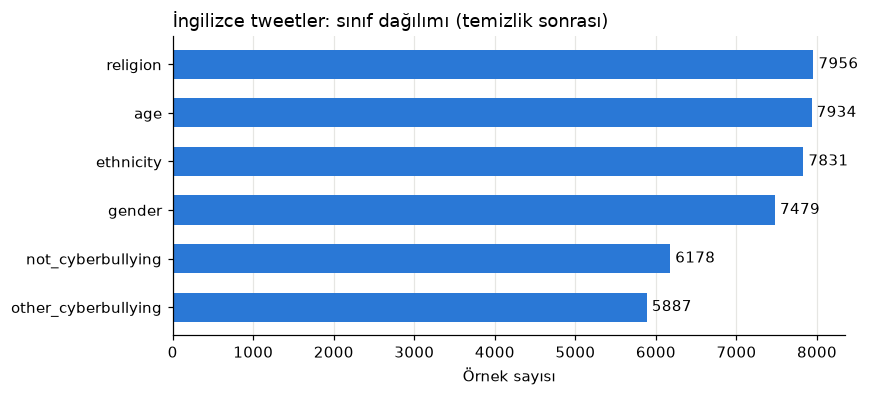

In [26]:
tweet = pd.read_csv(TWEET_DOSYASI)
tweet = veriyi_temizle(tweet, "tweet_text", "cyberbullying_type")

sinif_dagilimi_grafigi(tweet["cyberbullying_type"], "İngilizce tweetler: sınıf dağılımı (temizlik sonrası)",
                       "02_tweet_sinif_dagilimi.png")

#### **ANALİZ**
- **3.514 satır, aynı metnin farklı etiketlerle tekrarıydı** (ör. aynı tweet hem "gender" hem "not_cyberbullying"). Bu satırları çıkardık; aksi halde model birbiriyle çelişen örneklerden öğrenecekti.
- Temizlikten sonra 43.265 tweet kaldı. Sınıflar hâlâ dengeye yakın; en çok satır kaybeden sınıflar not_cyberbullying ve other_cyberbullying.

### 1.2 Model

- **TF-IDF (ngram_range=(1, 2)):** tek kelimeleri ve iki kelimelik ifadeleri ("you are", "dumb girl") özellik olarak kullanır.
- **min_df=2:** en az 2 tweette geçmeyen ifadeleri yok sayar.
- **make_pipeline:** iki adımı (TF-IDF → lojistik regresyon) tek bir model gibi birleştirir.
- **stratify=y:** eğitim ve test setlerinde sınıf oranlarının aynı kalmasını sağlar.

In [27]:
egitim_x, test_x, egitim_y, test_y = train_test_split(
    tweet["tweet_text"], tweet["cyberbullying_type"],
    test_size=0.2, stratify=tweet["cyberbullying_type"], random_state=42,
)

model_tweet = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000),
)
model_tweet.fit(egitim_x, egitim_y)
tahmin_tweet = model_tweet.predict(test_x)

print(classification_report(test_y, tahmin_tweet, digits=3))

                     precision    recall  f1-score   support

                age      0.955     0.982     0.968      1587
          ethnicity      0.976     0.976     0.976      1566
             gender      0.923     0.868     0.895      1496
  not_cyberbullying      0.730     0.642     0.683      1236
other_cyberbullying      0.705     0.780     0.741      1177
           religion      0.930     0.969     0.949      1591

           accuracy                          0.883      8653
          macro avg      0.870     0.870     0.869      8653
       weighted avg      0.882     0.883     0.882      8653



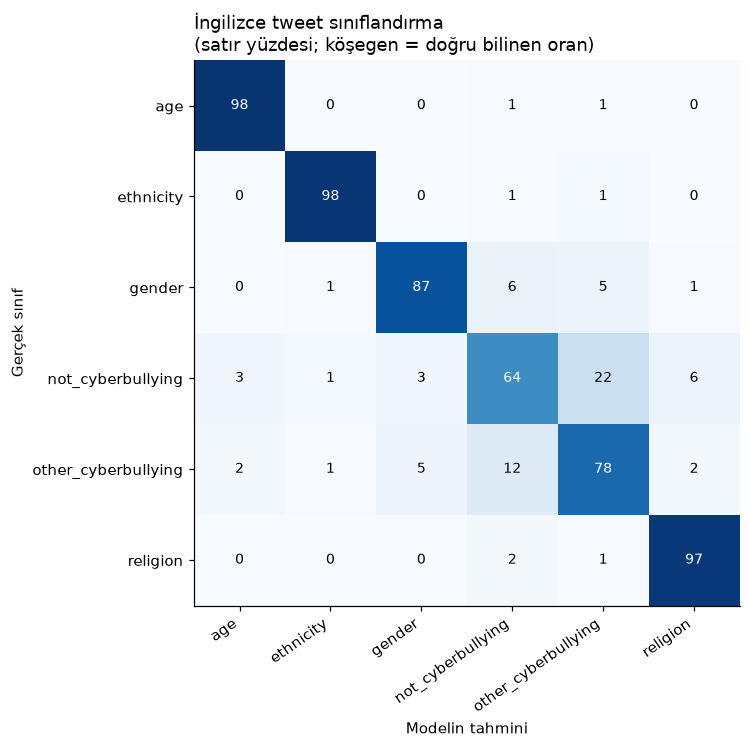

In [28]:
karisiklik_matrisi_grafigi(test_y, tahmin_tweet, "İngilizce tweet sınıflandırma", "02_tweet_karisiklik.png")

### **ANALİZ**

- Model genel olarak başarılı. Test setinde **macro-F1 = 0.869**, doğruluk %88.
- **Yaş, etnisite ve din** temelli zorbalık çok iyi tespit ediliyor (F1 = 0,95–0,98). Bu tweetlerde konuyu ele veren belirgin kelimeler var. Veri seti bu tür anahtar kelimelerle toplanmış olabilir; bu durumda skorlar gerçek hayattakinden yüksek görünebilir (**hipotez**, doğrulamadık).
- `not_cyberbullying` ile `other_cyberbullying` karışıklık matrisinde zorbalık olmayan tweetlerin %22'si "diğer zorbalık" olarak tahmin ediliyor. Belirli bir hedefi olmayan zorbalığı sıradan tweetten ayırmak, kelimelere dayalı bir model için zor.

## Bölüm 2: Bangla Dili Taciz Verisi (BanglaHarassNet)

### 2.1 Veriyi okuma

In [29]:
dosyalar = {
    "Neutral":           "Neutral .xlsx",      # dikkat: dosya adının sonunda boşluk var
    "Trolling":          "Trolling.xlsx",
    "Cyberbullying":     "Cyberbullying.xlsx",
    "Hate Speech":       "Hate Speech.xlsx",
    "Sexual Harassment": "Sexual Harassment.xlsx",
}

parcalar = []
for sinif, dosya in dosyalar.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")    # tarih sütunundaki bozuk hücre uyarılarını gizle
        d = pd.read_excel(BANGLA_KLASORU / dosya, header=1)   # başlıklar 2. satırda

    bos_satir = d["Text_Content"].isna().sum()
    d = d.dropna(subset=["Text_Content"])
    d["Tur"] = sinif
    parcalar.append(d)
    print(f"{sinif:18s}: {len(d):5d} metin   ({bos_satir} boş satır atıldı)")

bangla = pd.concat(parcalar, ignore_index=True)    # beş tabloyu alt alta birleştir

# Platform ve dil adlarındaki yazım farklarını birleştir ('Reddiit' → 'reddit', 'TikTok' / 'tiktok' → 'tiktok')
bangla["Platform"] = bangla["Platform"].astype(str).str.strip().str.lower().replace({"reddiit": "reddit"})
bangla["Language"] = bangla["Language"].astype(str).str.strip().str.lower()

Neutral           :  1299 metin   (0 boş satır atıldı)
Trolling          :  1088 metin   (4409 boş satır atıldı)
Cyberbullying     :  1258 metin   (4241 boş satır atıldı)
Hate Speech       :  1039 metin   (4461 boş satır atıldı)
Sexual Harassment :  1098 metin   (4399 boş satır atıldı)


Başlangıçtaki satır sayısı : 5782
Çelişkili etiketli satır: 104
Tekrar eden satır: 97
Temizlik sonrası satır: 5581


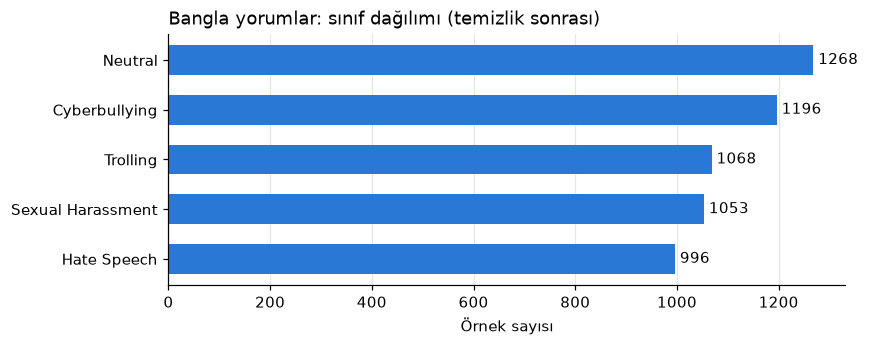

In [30]:
bangla = veriyi_temizle(bangla, "Text_Content", "Tur")
bangla["Text_Content"] = bangla["Text_Content"].astype(str)

sinif_dagilimi_grafigi(bangla["Tur"], "Bangla yorumlar: sınıf dağılımı (temizlik sonrası)",
                       "02_bangla_sinif_dagilimi.png")

### **ANALİZ**
- Excel dosyalarındaki satırların büyük kısmı boş; gerçek veri **5.782 yorum**.


### 2.2 Sınıflar nereden toplanmış? (Platform ve dil)

In [31]:
print("Platformlara göre sınıf dağılımı (sayı):")
print(pd.crosstab(bangla["Platform"], bangla["Tur"])) 
# crosstab: iki ve daha fazla platform varsa sütunlar çok olur, o zaman normalize="columns" ile yüzdeleri görmek daha iyi olur.

print("\nDile göre sınıf dağılımı (her sınıfın yüzdesi):")
print((pd.crosstab(bangla["Language"], bangla["Tur"], normalize="columns") * 100).round(1))

Platformlara göre sınıf dağılımı (sayı):
Tur        Cyberbullying  Hate Speech  Neutral  Sexual Harassment  Trolling
Platform                                                                   
facebook             851          690      182                203       162
instagram            154          104       69                350       209
reddit                 0            5      101                  0         0
tiktok                75           64      392                138       403
twitter/x             15           16       77                  6         4
youtube              101          117      447                356       290

Dile göre sınıf dağılımı (her sınıfın yüzdesi):
Tur       Cyberbullying  Hate Speech  Neutral  Sexual Harassment  Trolling
Language                                                                  
bangla             73.5         81.2     75.9               65.4      78.7
banglish           23.3         16.3      6.9               26.5      16.6
en

### **ANALİZ**

- Reddit yorumlarının neredeyse tamamı Neutral sınıfında. TikTok yorumları Neutral ve Trolling'de, Facebook yorumları Cyberbullying ve Hate Speech'te yoğunlaşıyor.
- İngilizce yorumlar Neutral sınıfının %16'sını oluşturuyor.

### 2.3 Metin modeli

Bangla için kelime yerine karakter parçaları kullanıyoruz. Bangla'da aynı kelime farklı ekler ve yazımlarla geçebiliyor; karakter parçaları bu çeşitliliği daha iyi yakalıyor. Örneğin "salaklar" kelimesi "sa", "al", "sal", "lak", "aklar"… gibi parçalara bölünür. class_weight="balanced küçük sınıflara biraz daha ağırlık verir.

In [32]:
egitim_x, test_x, egitim_y, test_y = train_test_split(
    bangla["Text_Content"], bangla["Tur"],
    test_size=0.2, stratify=bangla["Tur"], random_state=42,
)

model_bangla = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)
model_bangla.fit(egitim_x, egitim_y)
tahmin_bangla = model_bangla.predict(test_x)

print(classification_report(test_y, tahmin_bangla, digits=3))

                   precision    recall  f1-score   support

    Cyberbullying      0.687     0.607     0.644       239
      Hate Speech      0.387     0.372     0.379       199
          Neutral      0.641     0.598     0.619       254
Sexual Harassment      0.475     0.540     0.506       211
         Trolling      0.471     0.523     0.496       214

         accuracy                          0.534      1117
        macro avg      0.532     0.528     0.529      1117
     weighted avg      0.542     0.534     0.537      1117



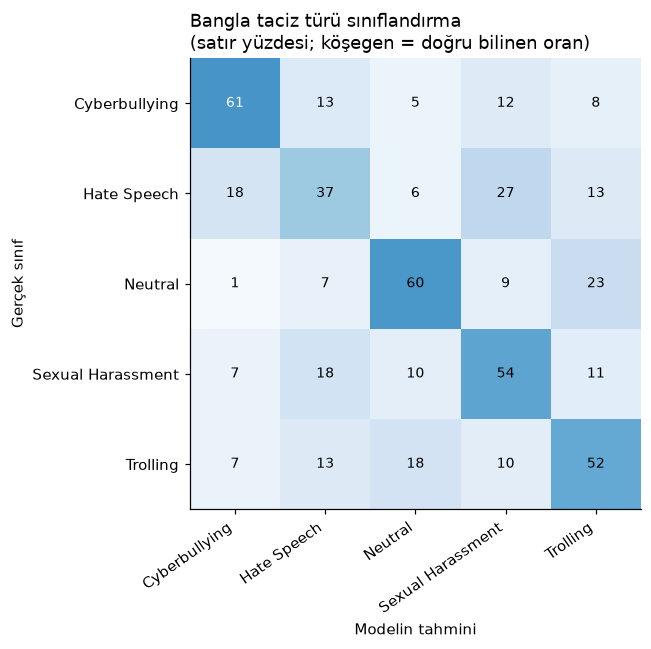

In [33]:
karisiklik_matrisi_grafigi(test_y, tahmin_bangla, "Bangla taciz türü sınıflandırma", "02_bangla_karisiklik.png")

### **ANALİZ**

**Cyberbullying (Siber Zorbalık):** %61 ile modelin en yüksek doğrulukla tespit ettiği sınıftır. Yanlış tahminlerde bu metinler en çok %13 oranında Nefret Söylemi (Hate Speech) ve %12 oranında Cinsel Taciz (Sexual Harassment) olarak sınıflandırılmıştır.

**Hate Speech (Nefret Söylemi):** %37 ile modelin tahmin etmekte en çok zorlandığı, performansı en düşük kategoridir. Gerçekte nefret söylemi olan metinlerin büyük bir kısmı (%27) Cinsel Taciz, bir kısmı ise (%18) Siber Zorbalık olarak yanlış etiketlenmiştir.

**Neutral (Nötr):** %60 oranında doğru tahmin edilmiştir. En belirgin hata, nötr metinlerin %23 gibi yüksek bir oranda Trolling (Trolleme) olarak algılanmasıdır.

**Sexual Harassment (Cinsel Taciz):** %54 oranında doğru bilinmiştir. Bu sınıf en sık (%18) Nefret Söylemi kategorisiyle karıştırılmıştır.

**Trolling (Trolleme):** %52 oranında doğru sınıflandırılmıştır. Model bu kategorideki metinleri %18 oranında Nötr olarak yanlış değerlendirmiştir.

## 3. Sonuç

Metin sınıflandırma modeli, zorbalığı türüne göre (yaş, cinsiyet, etnisite, din, taciz, nefret söylemi, trolling) içerikten tespit edebiliyor. İngilizce tweetlerde başarılıyken Bangla yorumlarda zayıf kaldı.
